# Gradiente conjugado con diafonía frente a gradiente conjugado en el dispositivo con diafonía

**Pregunta:** En un dispositivo cuyos píxeles se filtran entre sí, ¿qué recupera un optimizador de gradiente conjugado que tiene el núcleo de diafonía en su modelo (M13) frente al mismo optimizador sobre el modelo ideal (M10)?

- Nivel: 3, estado del arte. Método ejecutado: M13.
- Requisitos previos: `06-device-and-aberrations/01-what-the-device-costs`, que mide lo que cuesta cada efecto del dispositivo, y `05-optimization/03-conjugate-gradient-against-weighted-gs` para M10.
- Tiempo de lectura: unos 25 minutos. El notebook se ejecuta en cerca de un minuto.

## Objetivos

El notebook anterior del tema midió lo que cuesta un dispositivo a un holograma calculado para la pantalla ideal, y la diafonía fue el efecto que importó. La diafonía es una operación lineal conocida, así que un optimizador puede incluirla en su modelo. M13 lo hace: es M10, gradiente conjugado sobre el costo del tema anterior, ejecutado sobre el campo focal que el dispositivo realmente produce. Al terminar puedes:

- decir qué pone M13 en su modelo directo y qué deja fuera;
- medir M13 frente a M10 desde el mismo inicio en el dispositivo del caso C08, con el evaluador único del pipeline;
- leer cuántas iteraciones hace M13 antes de detenerse, y qué dice eso;
- comprobar que M13 sin dispositivo es M10, bit por bit;
- decir con qué ninguna implementación de referencia permite comparar M13.

## Preparación


El entorno de notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` en Windows). Este notebook usa dos paquetes, con estas versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica un paquete propio: sus métodos viven en la carpeta del pipeline `data-pipeline/`, y la celda siguiente
pone esa carpeta en la ruta de importación e importa las funciones que el notebook llama.

In [1]:
# las herramientas, sus versiones y la carpeta del pipeline en la ruta de importación
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.core import score as scoring
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.device import Device, pixel_envelope
from pipeline.model.holo.core.forward import trap_bins
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m06_gsw
from pipeline.model.holo.methods.optim import m10_cg, m13_crosstalk_cg

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Datos

El notebook lee el caso C08 de `data/examples/cases.json`: un arreglo de 8 x 8 en un SLM de 128 x 128 píxeles, con los parámetros de dispositivo del caso.

- Propietario: este repositorio; el caso es sintético, y sus parámetros de diafonía son los ajustados por Schroff et al. (2023).
- Clase de licencia: datos generados bajo la licencia del propio repositorio, sin conjuntos de datos de terceros.
- Archivo: `data/examples/cases.json`, caso C08.

In [2]:
# caso C08: un arreglo de 8 x 8 en un dispositivo con fase de 4 bits, diafonía, factor de llenado de 0.85 y
# parpadeo
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C08"]
setup = build.setup_of(rec)
target = build.target_of(rec)
device_c08 = build.device_of(rec)
print(rec["case_id"], "|", len(target.traps), "trampas | SLM", setup.n_pix, "x", setup.n_pix, "píxeles")
print(device_c08)

C08_device_limited | 64 trampas | SLM 128 x 128 píxeles
Device(bit_depth=4, crosstalk=(1.24, 1.8), upsample=3, fill_factor=0.85, flicker_rad=0.05, lut_gamma=1.0)


## Método

Schroff et al. (2023) modelan un SLM pixelado sobremuestreando cada píxel a 3 x 3 píxeles de cómputo, convolucionando la fase con el núcleo $K = \mathcal{F}^{-1}\{\exp[-(|k_x|^q + |k_y|^q)/\sigma^q]\}$ con $\sigma = 1{,}24$ y $q = 1{,}80$, y transformando el resultado; su optimizador es gradiente conjugado con el gradiente por diferenciación automática. M13 conserva el modelo y reemplaza la diferenciación automática por una forma cerrada: el adjunto del operador de diafonía es la convolución con el núcleo invertido seguida de la suma sobre cada bloque de 3 x 3, de modo que el gradiente cuesta una aplicación directa y una adjunta del modelo sobremuestreado. El modelo de M13 es el `device` que se le da: diafonía, la envolvente de la apertura del píxel y el cuantizador, que se aplica en el paso hacia adelante y se trata como identidad en el paso hacia atrás (un estimador de paso directo); el parpadeo se omite del modelo, porque es aleatorio. El costo es el del tema anterior, $C_2$ sobre los campos de las trampas del dispositivo, con la eficiencia objetivo 0,9.

## Estado del arte

M13 es un método del estado del arte: Schroff et al. informan, en un disco grande, un error de 1,9 por ciento con el modelo de diafonía frente a 2,7 por ciento sin él, con una eficiencia de 28 frente a 34 por ciento, y un tiempo de ejecución cerca de seis veces mayor. No existe una implementación de referencia fijada de él entre las dependencias del notebook (slmsuite no tiene un modelo de diafonía), así que la comparación es con M10 desde el mismo inicio, con el mismo costo y el mismo evaluador, en el arreglo de trampas del caso C08 con su dispositivo de 4 bits, diafonía, factor de llenado y parpadeo. La primera celda calcula el holograma desde el que parten ambos y lo evalúa.

In [3]:
# el holograma calculado para la pantalla ideal (GS ponderado, 30 iteraciones), evaluado en el dispositivo
# del caso
res06 = m06_gsw.run(setup, target, budget=Budget(30), rng=Rng(1))
on_device = {"M06": scoring.score(rec, res06.phi, setup=setup)}
s = on_device["M06"]
print(f"M06: eficiencia {s['efficiency']:.4f}  uniformidad {s['uniformity']:.4f}  desv. rel. {s['rel_std_pct']:.2f} %")

M06: eficiencia 0.6849  uniformidad 0.7028  desv. rel. 13.99 %


El holograma de GS ponderado, calculado para la pantalla ideal, tiene una desviación estándar relativa de 13,99 por ciento en el dispositivo y una eficiencia de 0,6849. M10 lo refina durante 60 iteraciones sobre el modelo ideal, con el mismo costo, que no ve la diafonía.

In [4]:
# M10 lo refina durante 60 iteraciones sobre el modelo ideal, que no ve el dispositivo
res10 = m10_cg.run(setup, target, budget=Budget(60), rng=Rng(1), init=res06.phi)
on_device["M10"] = scoring.score(rec, res10.phi, setup=setup)
s = on_device["M10"]
print(f"M10: eficiencia {s['efficiency']:.4f}  uniformidad {s['uniformity']:.4f}  desv. rel. {s['rel_std_pct']:.2f} %")

M10: eficiencia 0.6868  uniformidad 0.6922  desv. rel. 13.56 %


M10 termina en 13,56 por ciento con una eficiencia de 0,6868: optimizar el costo ideal no hace nada por el dispositivo. Ahora M13, con el dispositivo en su modelo, desde el mismo inicio y durante 5 iteraciones.

In [5]:
# M13, con el núcleo de diafonía, la apertura y el cuantizador en su modelo, durante 5 iteraciones
res13a = m13_crosstalk_cg.run(setup, target, device=device_c08, budget=Budget(5), rng=Rng(1), init=res06.phi)
on_device["M13, 5 it."] = scoring.score(rec, res13a.phi, setup=setup)
s = on_device["M13, 5 it."]
print(f"M13, 5 it.: {res13a.meta['iterations']} iteraciones hechas")
print(f"eficiencia {s['efficiency']:.4f}  uniformidad {s['uniformity']:.4f}  desv. rel. {s['rel_std_pct']:.2f} %")

M13, 5 it.: 3 iteraciones hechas
eficiencia 0.6749  uniformidad 0.7897  desv. rel. 8.15 %


M13 llega a 8,15 por ciento y a una uniformidad de 0,7897 en pocas iteraciones. Se hace de nuevo la misma llamada con un presupuesto de 60, el presupuesto que se le dio a M10.

In [6]:
# lo mismo, durante 60 iteraciones: el presupuesto de M10
res13b = m13_crosstalk_cg.run(setup, target, device=device_c08, budget=Budget(60), rng=Rng(1), init=res06.phi)
on_device["M13, 60 it."] = scoring.score(rec, res13b.phi, setup=setup)
s = on_device["M13, 60 it."]
print(f"M13, 60 it.: {res13b.meta['iterations']} iteraciones hechas")
print(f"eficiencia {s['efficiency']:.4f}  uniformidad {s['uniformity']:.4f}  desv. rel. {s['rel_std_pct']:.2f} %")

M13, 60 it.: 3 iteraciones hechas
eficiencia 0.6749  uniformidad 0.7897  desv. rel. 8.15 %


El resultado es idéntico al de 5 iteraciones: la línea dice 3 iteraciones hechas, así que el gradiente conjugado se detiene tras tres pasos sea cual sea el presupuesto, y la eficiencia y la dispersión no cambian. El notebook no aisló la causa; una probable es que el gradiente de paso directo del cuantizador no es la derivada del costo cuantizado, de modo que la búsqueda de línea no encuentra descenso a lo largo de la dirección. El control que sigue comprueba el otro extremo del método: sin dispositivo en su modelo, M13 debe ser M10.

In [7]:
# el control: M13 sin dispositivo en su modelo debe ser M10, fase por fase
plain13 = m13_crosstalk_cg.run(setup, target, device=None, budget=Budget(10), rng=Rng(1), init=res06.phi)
plain10 = m10_cg.run(setup, target, budget=Budget(10), rng=Rng(1), init=res06.phi)
print(f"mayor diferencia de fase entre M13 sin dispositivo y M10: "
      f"{np.abs(plain13.phi - plain10.phi).max():.2e} rad")

mayor diferencia de fase entre M13 sin dispositivo y M10: 0.00e+00 rad


M13 sin dispositivo y M10 dan fases que difieren en 0,00e+00 rad, así que el modelo y nada más es lo que cambia entre ellos. La figura pone lado a lado los cinco hologramas del notebook, con la dispersión a la izquierda y las intensidades ordenadas de las trampas de tres de ellos a la derecha.

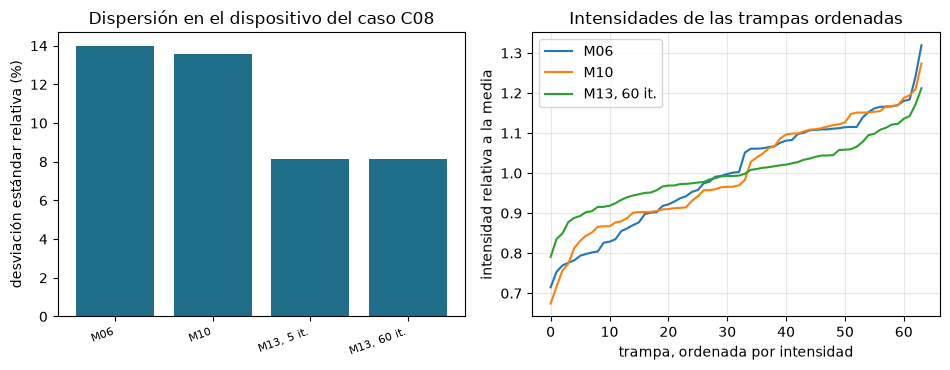

In [8]:
# desviación estándar relativa en el dispositivo de cada holograma, y las intensidades ordenadas de tres de
# ellos
fig, (a, b) = plt.subplots(1, 2, figsize=(9.6, 3.8))
names = list(on_device)
a.bar(range(len(names)), [on_device[k]["rel_std_pct"] for k in names], color="#1f6f8b")
a.set_xticks(range(len(names)))
a.set_xticklabels(names, rotation=20, ha="right", fontsize=8)
a.set_ylabel("desviación estándar relativa (%)")
a.set_title("Dispersión en el dispositivo del caso C08")
for name in ("M06", "M10", "M13, 60 it."):
    b.plot(np.sort(on_device[name]["trap_intensity"]), label=name)
b.set_xlabel("trampa, ordenada por intensidad")
b.set_ylabel("intensidad relativa a la media")
b.set_title("Intensidades de las trampas ordenadas")
b.legend()
b.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

M10 y M06 están al mismo nivel, 13,56 y 13,99 por ciento, y las dos barras de M13 están en 8,15 por ciento: el optimizador que conoce la diafonía elimina 40 por ciento de la dispersión que deja M10, con una uniformidad de 0,7897 frente a 0,6922. En las curvas ordenadas la línea de M13 es plana en el centro y sus extremos son más cerrados que los de M06 y M10. Lo paga en luz: la eficiencia es 0,6749 frente a 0,6868, una pérdida de 0,012. El piso que queda, 8,15 por ciento frente a los 4,12 de la apertura sola del notebook anterior, viene del cuantizador y del parpadeo, que el modelo de M13 trata como identidad o deja fuera. La figura es de un inicio, una semilla y un dispositivo; el disco del artículo es otro problema, y el notebook no lo repite.

La última figura muestra dónde movió el holograma el optimizador que conoce la diafonía: la diferencia envuelta, píxel a píxel, entre el patrón de fase de M13 y el patrón de GS ponderado del que partió.

cambio rms 0.0703 rad | mayor 0.301 rad
fracción de píxeles sobre 0.1 rad: 0.151


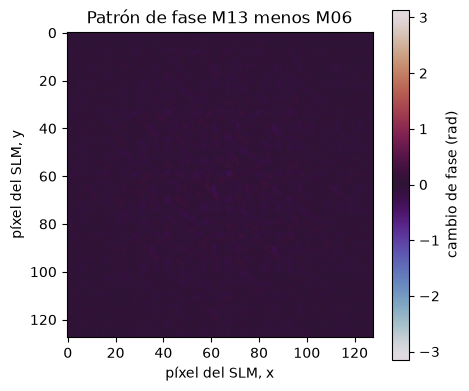

In [9]:
# lo que cambió M13 en el holograma: la diferencia de fase envuelta entre los patrones de M13 y de M06
change = np.angle(np.exp(1j * (res13b.phi - res06.phi)))
print(f"cambio rms {np.sqrt(np.mean(change ** 2)):.4f} rad | mayor {np.abs(change).max():.3f} rad")
print(f"fracción de píxeles sobre 0.1 rad: {np.mean(np.abs(change) > 0.1):.3f}")
fig, ax = plt.subplots(figsize=(4.8, 4.2))
image = ax.imshow(change, cmap="twilight", vmin=-np.pi, vmax=np.pi)
fig.colorbar(image, ax=ax, label="cambio de fase (rad)")
ax.set_xlabel("píxel del SLM, x")
ax.set_ylabel("píxel del SLM, y")
ax.set_title("Patrón de fase M13 menos M06")
plt.tight_layout()
plt.show()

El cambio es pequeño y está repartido en toda la apertura: el rms es 0,0703 rad y el mayor cambio 0,301 rad, y 15,1 por ciento de los píxeles se mueven más de 0,1 rad. En la escala de colores de una vuelta completa la figura es casi uniformemente oscura, con un grano tenue a la escala de píxeles individuales algo más fuerte cerca del centro, donde el haz lleva más luz. Esa es toda la diferencia entre un holograma que muestra 13,99 por ciento de dispersión en el dispositivo y uno que muestra 8,15 por ciento: una predistorsión de unas pocas centésimas de radián por píxel, que un gráfico de los propios patrones no podría revelar. La figura no muestra si una corrida más larga encontraría una corrección mayor, ya que el optimizador se detuvo tras tres iteraciones.

## Resultados

**Respuesta:** Un optimizador de gradiente conjugado con el núcleo de diafonía en su modelo recupera parte de lo que cuesta la diafonía, y el mismo optimizador sobre el modelo ideal no recupera nada. Desde el mismo inicio de GS ponderado, en el dispositivo del caso C08, M10 termina con una desviación estándar relativa de 13,56 por ciento frente a 13,99 del inicio, mientras M13 llega a 8,15 por ciento y a una uniformidad de 0,7897 (0,6922 para M10), eliminando 40 por ciento de la dispersión que deja M10, por 0,012 de la luz (una eficiencia de 0,6749 frente a 0,6868). M13 se detiene tras tres iteraciones sea cual sea el presupuesto, 5 o 60, de modo que su resultado no mejora con el esfuerzo, y sin dispositivo en su modelo es igual a M10 con 0,00e+00 rad.

Lo que el notebook no muestra es el disco grande del artículo, la causa de la detención temprana, ni una implementación independiente de M13, que no existe entre las dependencias.

## Resumen

- M13 es M10 ejecutado sobre el campo focal del dispositivo: núcleo de diafonía, apertura del píxel y un cuantizador de paso directo, con el adjunto del núcleo en forma cerrada.
- En el dispositivo de C08 reduce la dispersión de 13,56 por ciento (M10) a 8,15 por ciento, por 0,012 de la luz.
- Se detiene tras tres iteraciones sea cual sea el presupuesto, y no se aisló la causa.
- Sin dispositivo es exactamente igual a M10.
- No existe una implementación de referencia fijada de M13 entre las dependencias.

## Referencias

- Schroff et al. (2023). Accurate holographic light potentials using pixel crosstalk modelling. Scientific Reports 13, 3252. https://doi.org/10.1038/s41598-023-30296-6
- Harte et al. (2014). A conjugate gradient minimisation approach to generating holographic traps for ultracold atoms. Optics Express 22, 26548. https://doi.org/10.1364/OE.22.026548